# Bank Customer Response Prediction

**Goal:** predict which bank clients are likely to subscribe to a term deposit after a marketing call, so the bank can call the most promising clients first and waste fewer calls.
**Dataset:** UCI Bank Marketing (`bank-additional-full.csv`): 41,188 phone calls from a Portuguese bank, 20 input columns and a yes/no target `y`. Only about 11% of clients say yes.
*Note: the target is "did the client subscribe", not "did the client leave", so this is a response/retention propensity problem rather than literal churn. The ML workflow is the same.*

## Contents
| Part | Section | What it does |
|---|---|---|
| 1 | Data cleaning | Audit the raw data and fix its problems |
| 2 | Split, EDA and preprocessing | Train/test split, exploration, preprocessing recipe |
| 3 | Model training and evaluation | Compare models, final test score, business result |
| 4 | Model explanation | What drives the model's predictions |

## Results at a glance
| Model | CV ROC-AUC | CV PR-AUC |
|---|---|---|
| Logistic regression | 0.791 | 0.446 |
| Random forest | 0.795 | 0.466 |
| Gradient boosting (HistGB, final) | 0.799 | 0.466 |

**Test set (HistGB, used once):** ROC-AUC **0.813**, PR-AUC **0.488** (a random model scores about 0.113 on PR-AUC).

| Clients called (ranked by model) | Subscribers captured | Lift vs. random calling |
|---|---|---|
| Top 10% | 45% | 4.5x |
| Top 20% | 66% | 3.3x |
| Top 30% | 75% | 2.5x |
| Top 50% | 84% | 1.7x |

Calling only the top 20% reaches about two thirds of all subscribers with 80% fewer calls.
The model leans mostly on **economic indicators** (which mainly tell it *when* the call happened) and on **contact type** (cellular beats telephone).

## Setup
Mounts Google Drive and imports the libraries. This project was run in Google Colab with files in Google Drive; if you run it locally, skip the Drive lines and edit the two paths.

In [49]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Part 1: Data Cleaning
**What this part does:** takes the raw file, checks it for problems, fixes them and saves a clean copy (41,176 rows, 21 columns).

**What we found**
- No true blank cells, but the mess is hidden inside special values.
- 12 duplicate rows.
- Imbalanced target: only 11.3% say yes.
- "unknown" values in six text columns, worst in `default` (20.9%) and `education` (4.2%).
- `pdays = 999` is a code meaning "never contacted before", not a real number of days.
- `duration` (call length) is only known after the call ends, so using it would be cheating (data leakage).

**What we did**
1. Dropped the duplicates. 2. Dropped `duration`. 3. Replaced `pdays = 999` with a blank and added a `previously_contacted` flag. 4. Converted the target: yes becomes 1, no becomes 0. 5. Kept "unknown" as its own category instead of guessing a value, since it may carry information.

### 1.1 Load the raw data
The file is **semicolon-separated**, so we need `sep=";"`. Without it, pandas reads each whole row as one giant column.

In [51]:
df = pd.read_csv("/content/drive/MyDrive/Customer response prediction/bank-additional-full.csv",sep=";")

### 1.2 First look
Shape, column names, data types and the first rows.

In [52]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [54]:
df.shape

(41188, 21)

In [55]:
df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'housing',
 'loan',
 'contact',
 'month',
 'day_of_week',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'emp.var.rate',
 'cons.price.idx',
 'cons.conf.idx',
 'euribor3m',
 'nr.employed',
 'y']

### 1.3 Audit
Four checks: true missing values, duplicate rows, target balance, and hidden missing values stored as "unknown".

**Missing values** (blank cells). The total is 0, so the dirt is stored as special values instead.

In [56]:
df.isna().sum().sum()

np.int64(0)

**Duplicate rows.** There are 12. We drop them before splitting so the same row can't land in both train and test.

In [57]:
df.duplicated().sum()

np.int64(12)

**Target balance** (percentage of no/yes). Only about 11% say yes, so accuracy would be a misleading metric. We use ROC-AUC and PR-AUC instead.

In [58]:
df["y"].value_counts(normalize=True)*100

,proportion
y,
no,88.734583
yes,11.265417


**"unknown" counts.** Not blanks, but missing information. `default` is the worst at about 21%.

In [59]:
print("\n'unknown' counts:")
for c in df.select_dtypes("object"):
    n = (df[c] == "unknown").sum()
    if n: print(f"  {c}: {n} ({n/len(df):.1%})")


'unknown' counts:
  job: 330 (0.8%)
  marital: 80 (0.2%)
  education: 1731 (4.2%)
  default: 8597 (20.9%)
  housing: 990 (2.4%)
  loan: 990 (2.4%)


### 1.4 Clean the data
Five decisions, explained in the code comments. The result is saved to `bank_clean.csv`.

In [60]:
clean = df.copy()

# 1. Duplicates
clean = clean.drop_duplicates().reset_index(drop=True)

# 2. Leakage: duration is only known after the call
clean = clean.drop(columns=["duration"])

# 3. pdays: 999 means "never contacted before"
clean["previously_contacted"] = (clean["pdays"] != 999).astype(int)
clean["pdays"] = clean["pdays"].replace(999, np.nan)

# 4. Target
clean["y"] = (clean["y"] == "yes").astype(int)

clean.to_csv(CLEAN_PATH, index=False)
print(clean.shape)

(41176, 21)


# Part 2: Train/Test Split, EDA and Preprocessing
**What this part does:** splits the cleaned data into a training set and a test set, explores the training set to see which clients tend to say yes, and defines the recipe that turns the table into numbers a model can use.

**What we did**
1. **Stratified 80/20 split:** 32,940 training rows and 8,236 test rows. `stratify=y` keeps the yes-rate at 11.3% in both parts; `random_state=42` makes it repeatable.
2. **Exploration on training data only**, so the test set stays untouched.
3. **Preprocessing recipe:** numeric columns get blanks filled with the median and are scaled; text columns are one-hot encoded (each category becomes its own 0/1 column, with "unknown" kept as a category).

**What the exploration showed**
- Student (32%) and retired (26%) clients say yes far more often than average; blue-collar clients are lowest (7%).
- Cellular contact (15%) works much better than telephone (5%).
- Previous campaign success is the strongest group signal: 66% of those clients said yes again.
- Month matters, but check the counts: December and March look great (about 50%) on only 145 and 432 calls. May is the opposite: only 6.4% said yes, on 11,019 calls.
- Subscribers had been contacted more before (0.49 earlier contacts vs. 0.13) but were called fewer times in this campaign (2.05 vs. 2.63). Age barely differs.

### 2.1 Train/test split
The training set is for learning and choosing models. The test set is kept aside for one final, honest evaluation. Everything we explore or fit from here uses the training data only.

In [61]:
from sklearn.model_selection import train_test_split

X = clean.drop(columns="y")
y = clean["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(32940, 20) (8236, 20)
0.113 0.113


### 2.2 Exploratory analysis (training data only)
**Response rate by category.** `rate` is the share who said yes and `n` is the group size. Always read `n` next to `rate`: a high rate on a tiny group means little.

In [62]:
train = X_train.copy()
train["y"] = y_train

# Response rate by category
for c in ["job", "month", "contact", "poutcome", "education"]:
    print(f"\n{c}")
    print(train.groupby(c)["y"].agg(rate="mean", n="size")
               .sort_values("rate", ascending=False).round(3))


job
                rate     n
job                       
student        0.323   691
retired        0.258  1388
admin.         0.129  8269
unemployed     0.128   812
unknown        0.124   267
management     0.113  2340
technician     0.107  5420
housemaid      0.104   859
self-employed  0.103  1114
entrepreneur   0.086  1159
services       0.081  3181
blue-collar    0.069  7440

month
        rate      n
month              
dec    0.503    145
mar    0.498    432
sep    0.440    461
oct    0.435    581
apr    0.204   2084
aug    0.108   4953
jun    0.104   4248
nov    0.102   3264
jul    0.092   5753
may    0.064  11019

contact
            rate      n
contact                
cellular   0.147  20939
telephone  0.052  12001

poutcome
              rate      n
poutcome                 
success      0.660   1094
failure      0.140   3415
nonexistent  0.088  28431

education
                      rate     n
education                       
illiterate           0.222    18
unknown        

**Numeric features vs. the target.** Average value of each feature for clients who said no (0) and yes (1).

In [63]:
# Numeric features vs. target
print(train.groupby("y")[["age", "campaign", "previous"]].mean().round(2))

     age  campaign  previous
y                           
0  39.89      2.63      0.13
1  41.03      2.05      0.49


### 2.3 Preprocessing recipe
This cell only **defines** the recipe; it doesn't change any data yet. It is applied inside a `Pipeline` in Part 3, where each fitting step learns from training rows only, so nothing leaks in from the held-out data.
- **Numbers:** fill blanks (only `pdays`) with the median, then scale so large-valued columns don't dominate.
- **Text:** one-hot encode. "unknown" becomes its own column.

In [64]:
# PREPROCESSING
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes("number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

# Part 3: Model Training and Evaluation
**What this part does:** compares three models with cross-validation, picks the best one, scores it once on the untouched test set, and turns the result into a business number: how many subscribers do we reach if we only call the top-ranked clients?

**What we did**
1. Compared logistic regression, random forest and HistGradientBoosting with stratified 5-fold cross-validation on the training set, using `class_weight="balanced"` for the 11% imbalance.
2. Picked HistGB from the CV table and scored it once on the test set (results at the top of this notebook).
3. Ranked test clients by predicted chance of saying yes and checked how many real subscribers fall in the top slices.

All three models land within 0.01 ROC-AUC of each other, so most of the signal is in the data and a fancier model adds little.

### 3.1 Compare three models with cross-validation
Each model is wrapped in a `Pipeline` (recipe first, then the model), so preprocessing is re-learned inside every fold and the held-out fold stays truly unseen. Scores are averaged over 5 folds, on **training data only**.
- **ROC-AUC:** how often the model ranks a "yes" client above a "no" client (0.5 = coin flip, 1.0 = perfect).
- **PR-AUC:** stricter when "yes" is rare; a random model scores about 0.11 here.

In [65]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "LogReg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           class_weight="balanced", n_jobs=-1, random_state=42),
    "HistGB": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=["roc_auc", "average_precision"], n_jobs=-1)
    print(f"{name:13} ROC-AUC {s['test_roc_auc'].mean():.3f} | PR-AUC {s['test_average_precision'].mean():.3f}")

LogReg        ROC-AUC 0.791 | PR-AUC 0.446
RandomForest  ROC-AUC 0.795 | PR-AUC 0.466
HistGB        ROC-AUC 0.799 | PR-AUC 0.466


### 3.2 Final test score
The winner (HistGB, chosen from the CV table) is trained on all training data and scored **once** on the test set. Test scores close to the CV scores mean there is no sign of leakage.

In [66]:
from sklearn.metrics import roc_auc_score, average_precision_score

best = Pipeline([("prep", preprocess), ("model", models["HistGB"])])
best.fit(X_train, y_train)

proba = best.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("Test PR-AUC :", round(average_precision_score(y_test, proba), 3))

Test ROC-AUC: 0.813
Test PR-AUC : 0.488


### 3.3 Business result: how many subscribers do the top-ranked clients capture?
Test clients are sorted from most to least likely to say yes. For each slice (top 10%, 20%, ...) we check what share of the real subscribers it contains. Random calling would capture exactly the share called.

In [67]:
import pandas as pd

g = pd.DataFrame({"y": y_test.values, "p": proba}).sort_values("p", ascending=False)
total_yes = g["y"].sum()

for pct in [0.1, 0.2, 0.3, 0.5]:
    top = g.head(int(len(g) * pct))
    print(f"Call top {pct:.0%} -> captures {top['y'].sum() / total_yes:.0%} of subscribers")

Call top 10% -> captures 45% of subscribers
Call top 20% -> captures 66% of subscribers
Call top 30% -> captures 75% of subscribers
Call top 50% -> captures 84% of subscribers


**The actual top-20% list.** How many clients that is, what share really subscribed (37%, vs. 11% overall), and what the first few look like.

In [68]:
g = pd.DataFrame({"p": proba, "y": y_test.values}, index=X_test.index).sort_values("p", ascending=False)

top20 = g.head(int(len(g) * 0.2))
print(len(top20), "clients;", f"{top20['y'].mean():.0%} of them actually subscribed")

# see their original details
X_test.loc[top20.index].head()

1647 clients; 37% of them actually subscribed


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,previously_contacted
40551,59,admin.,married,university.degree,no,no,yes,cellular,sep,wed,1,3.0,1,success,-1.1,94.199,-37.5,0.886,4963.6,1
39728,70,retired,divorced,high.school,no,yes,no,telephone,may,wed,2,4.0,2,success,-1.8,93.876,-40.0,0.697,5008.7,1
40105,83,retired,married,university.degree,no,yes,no,cellular,jul,tue,1,6.0,2,success,-1.7,94.215,-40.3,0.835,4991.6,1
40544,69,retired,married,high.school,no,yes,yes,cellular,sep,wed,1,6.0,2,success,-1.1,94.199,-37.5,0.886,4963.6,1
40930,65,retired,married,basic.4y,no,yes,yes,cellular,oct,wed,1,3.0,3,success,-1.1,94.601,-49.5,0.985,4963.6,1


### 3.4 Gains chart
The same result as a picture. The further the model's curve rises above the dashed random-calling line, the better the ranking. The dotted vertical line marks the top 20%.

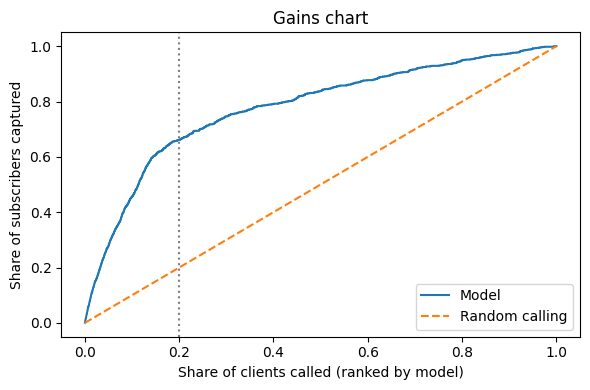

In [69]:
import matplotlib.pyplot as plt
import numpy as np

g = pd.DataFrame({"y": y_test.values, "p": proba}).sort_values("p", ascending=False)
captured = g["y"].cumsum() / g["y"].sum()
called = np.arange(1, len(g) + 1) / len(g)

plt.figure(figsize=(6, 4))
plt.plot(called, captured, label="Model")
plt.plot([0, 1], [0, 1], "--", label="Random calling")
plt.axvline(0.2, color="gray", linestyle=":")
plt.xlabel("Share of clients called (ranked by model)")
plt.ylabel("Share of subscribers captured")
plt.title("Gains chart")
plt.legend()
plt.tight_layout()
plt.savefig("gains_chart.png", dpi=150)
plt.show()

# Part 4: Model Explanation
**What this part does:** opens up the final model (HistGradientBoosting) to see which columns it relies on, using two methods.
- **Permutation importance:** scramble one column in the test set and measure how much the ROC-AUC drops. A big drop means the model needed that column.
- **SHAP:** for each client, how much each column pushed the predicted probability up or down. We average the size of those pushes; the beeswarm plot also shows direction.

The two rankings use different units, so compare the order, not the numbers.

**What we found**
- **Permutation importance (drop in ROC-AUC):** `nr.employed` 0.090, `contact` 0.024, `euribor3m` 0.021, `cons.price.idx` 0.016, `cons.conf.idx` 0.014, then `previously_contacted`, `campaign`, `month`.
- **SHAP by original column (average push on the probability):** `nr.employed` 0.069, `cons.price.idx` 0.029, `euribor3m` 0.027, `contact` 0.026, `cons.conf.idx` 0.024, then `age`, `campaign`, `previously_contacted`, `emp.var.rate`, `education`.
- Economic indicators dominate both rankings. Contact type (cellular vs. telephone) is the strongest client-level feature. `previously_contacted` and `campaign` give smaller but real effects.

**Limitations**
- The economic columns change slowly over time, so they mostly tell the model **when** the call happened rather than **who** was called. The data covers 2008 to 2010, so the model may not transfer to a different economic period.
- `nr.employed`, `euribor3m` and `emp.var.rate` are strongly correlated, so how importance is shared among them is somewhat arbitrary. Read them as a group.

### 4.1 Permutation importance
`best` is the whole pipeline, so the shuffling happens on the original columns (job, month, euribor3m...), which keeps the result readable.

In [70]:
from sklearn.inspection import permutation_importance
import pandas as pd

r = permutation_importance(
    best, X_test, y_test,
    scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1
)

imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.head(10).round(4))

nr.employed             0.0903
contact                 0.0241
euribor3m               0.0210
cons.price.idx          0.0162
cons.conf.idx           0.0136
previously_contacted    0.0054
campaign                0.0047
month                   0.0031
day_of_week             0.0029
default                 0.0018
dtype: float64


### 4.2 SHAP
SHAP needs the model's numeric input, so we explain the model on the already-prepared table. This takes a minute or two. The bar chart shows the overall ranking; in the beeswarm plot each dot is a client, and dots to the right push towards "yes". One-hot encoding splits each text column into pieces (for example `cat__poutcome_success`), so these first plots show the pieces.

In [71]:
!pip install shap

PermutationExplainer explainer: 301it [00:56,  4.65it/s]


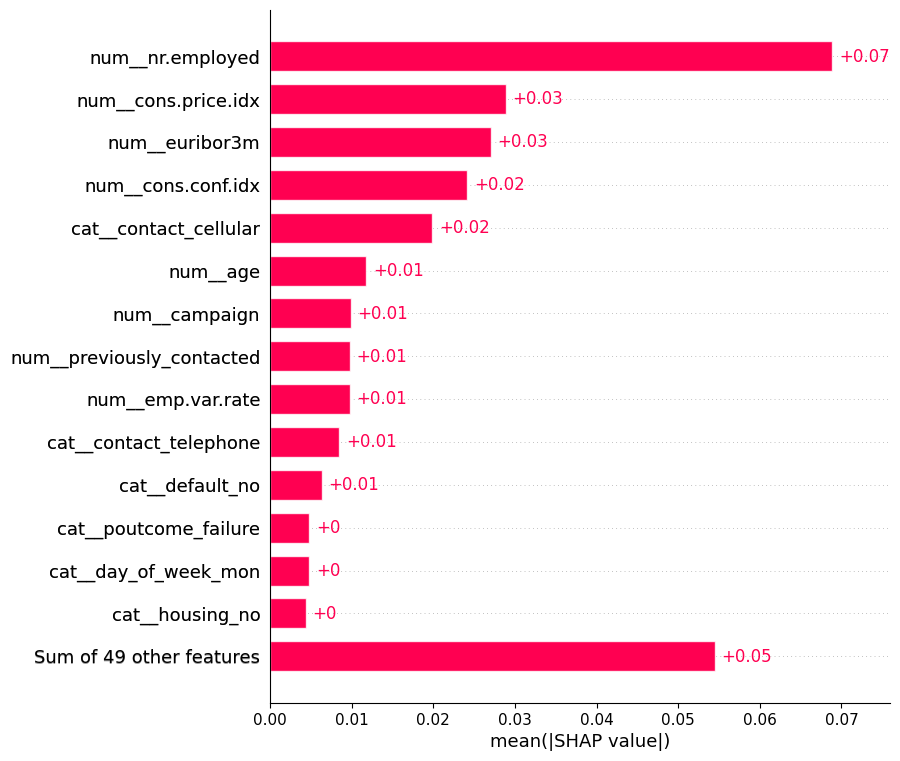

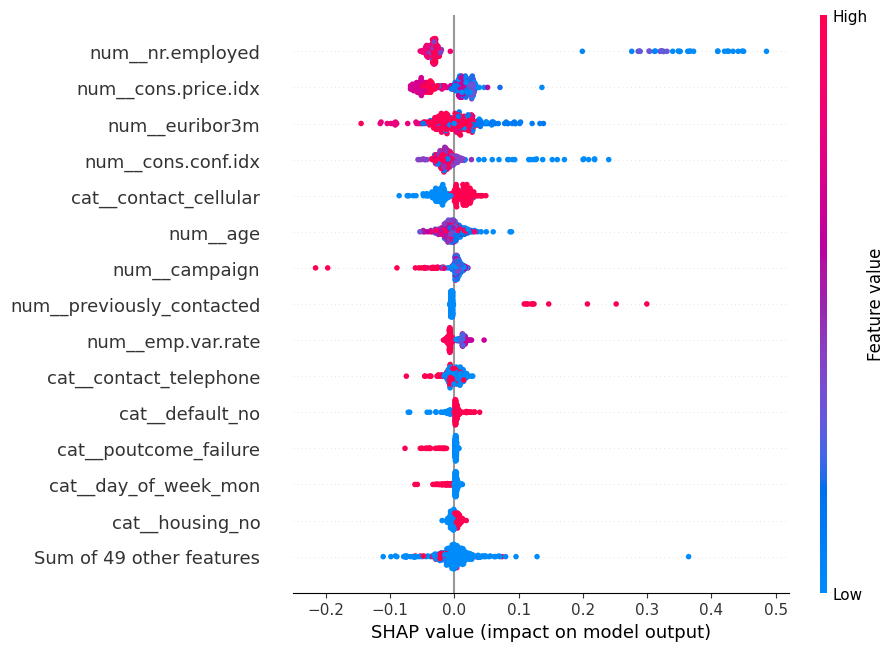

In [72]:
import shap, numpy as np, pandas as pd

prep = best.named_steps["prep"]
model = best.named_steps["model"]

bg = prep.transform(X_train.sample(100, random_state=42))     # background rows
smp = prep.transform(X_test.sample(300, random_state=42))     # clients to explain
names = prep.get_feature_names_out()

f = lambda d: model.predict_proba(d)[:, 1]
explainer = shap.Explainer(f, bg, feature_names=names)
sv = explainer(smp)

shap.plots.bar(sv, max_display=15)
shap.plots.beeswarm(sv, max_display=15)

### 4.3 SHAP importance by original column
Adds up the pieces of each one-hot encoded column (all `job_...` pieces become `job`), giving one score per original column.

In [73]:
cat_cols = list(cat_cols)
raw = {}
for i, n in enumerate(names):
    base = n.split("__", 1)[1]
    col = next((c for c in cat_cols if base.startswith(c + "_")), base)
    raw[col] = raw.get(col, 0) + sv.values[:, i]

imp = pd.Series({k: np.abs(v).mean() for k, v in raw.items()}).sort_values(ascending=False)
print(imp.head(10).round(4))

nr.employed             0.0689
cons.price.idx          0.0288
euribor3m               0.0270
contact                 0.0270
cons.conf.idx           0.0242
age                     0.0118
campaign                0.0099
previously_contacted    0.0098
emp.var.rate            0.0098
education               0.0083
dtype: float64


# End of the project
Clean the data (Part 1), split and prepare it (Part 2), compare and test models (Part 3), and explain the winner (Part 4).